#Practical 1

In [1]:
import csv

In [2]:
#!/bin/bash
!kaggle datasets download justsahil/movielens-32m
!unzip movielens-32m.zip

path = "/content/ml-32m"

Dataset URL: https://www.kaggle.com/datasets/justsahil/movielens-32m
License(s): apache-2.0
100% 231M/231M [00:03<00:00, 67.8MB/s]

Archive:  movielens-32m.zip
  inflating: ml-32m/README.txt       
  inflating: ml-32m/checksums.txt    
  inflating: ml-32m/links.csv        
  inflating: ml-32m/movies.csv       
  inflating: ml-32m/ratings.csv      
  inflating: ml-32m/tags.csv         


In [3]:
from collections import Counter
import matplotlib.pyplot as plt
import random

class DataStructures:
  ## **for practical 1**
  def __init__(self, path):

    ##initializing the indexing lists and dicts for users and items
    self.user_to_index = {}
    self.index_to_user = []
    self.item_to_index = {}
    self.index_to_item = []

    ## lists we will append tuples to as we are looping through the ratings file
    self.data_by_user = []
    self.data_by_item = []

    ## **for practical 2**
    ## lists for train and test sparse matrices (should be same size)
    self.data_by_user_train = []
    self.data_by_user_test = []
    self.data_by_item_train = []
    self.data_by_item_test = []
    self.cut_off = 0.2



    with open(path + "/ratings.csv") as ratings:
        rows = csv.reader(ratings, delimiter=',')
        iterations =0
        next(rows)
        for row in rows:
          userId, itemID, rating, _ = row

          if userId not in self.index_to_user:
            self.index_to_user.append(userId)
            self.user_to_index[userId] = len(self.index_to_user)-1
            self.data_by_user.append([])

            ## for practical 2 matrices (user ones)
            self.data_by_user_train.append([])
            self.data_by_user_test.append([])


          if itemID not in self.index_to_item:
            self.index_to_item.append(itemID)
            self.item_to_index[itemID] = len(self.index_to_item)-1
            self.data_by_item.append([])

            ## for practical 2 matrices (items ones)
            self.data_by_item_train.append([])
            self.data_by_item_test.append([])




          self.data_by_user[self.user_to_index[userId]].append((itemID, float(rating)))
          self.data_by_item[self.item_to_index[itemID]].append((userId, float(rating)))


          if random.random() >= self.cut_off:
            self.data_by_user_train[self.user_to_index[userId]].append((itemID, float(rating)))
            self.data_by_item_train[self.item_to_index[itemID]].append((userId, float(rating)))
          else:
            self.data_by_user_test[self.user_to_index[userId]].append((itemID, float(rating)))
            self.data_by_item_test[self.item_to_index[itemID]].append((userId, float(rating)))


          iterations += 1
          if iterations == 100000:
            break
  def plot_powerlaw(self):
    item_deg = Counter(len(r) for r in self.data_by_item)
    item_x = list(item_deg.keys())
    item_y = list(item_deg.values())

    user_deg = Counter(len(r) for r in self.data_by_user)
    user_x = list(user_deg.keys())
    user_y = list(user_deg.values())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(item_x, item_y, marker=".", linestyle="none",
    color="green", label="Items")
    ax1.plot(user_x, user_y, marker=".", linestyle="none",
    color="purple", label="Users")

    ax1.set_title("Normal scale")
    ax1.set_xlabel("Degree")
    ax1.set_ylabel("Frequency")
    ax1.grid(True)
    ax1.legend()

    ax2.loglog(item_x, item_y, marker=".", linestyle="none",
    color="green", label="Items")
    ax2.loglog(user_x, user_y, marker=".", linestyle="none",
    color="purple", label="Users")

    ax2.set_title("Log-log scale")
    ax2.set_xlabel("Degree")
    ax2.set_ylabel("Frequency")
    ax2.grid(True)
    ax2.legend()

    plt.tight_layout()
    plt.show()

In [27]:
print(data.data_by_user)

AttributeError: 'RatingMap' object has no attribute 'data_by_user'

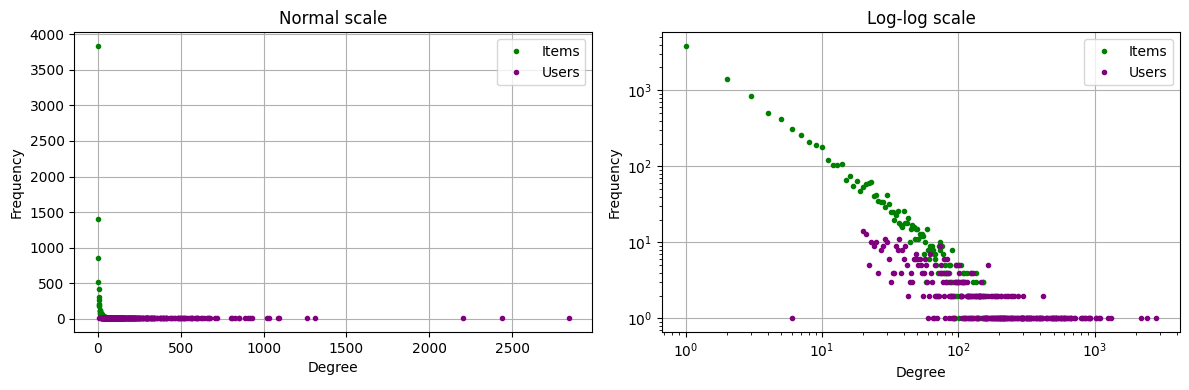

In [5]:
data = DataStructures(path)
data.plot_powerlaw()

In [26]:
print(data.data_by_item)
print (data.data_by_item_test[0])
print (data.data_by_item_train[0])
print (data.data_by_user_test[0])
print (data.data_by_user_train[0])

AttributeError: 'RatingMap' object has no attribute 'data_by_item'

#Data analysis (MovieLens 32M)

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

ratings_df = pd.read_csv(path + "/ratings.csv", names=["u", "i", "r"], header=0, usecols=[0, 1, 2],
                         dtype={"u": np.int32, "i": np.int32, "r": np.float32})
raw_users = ratings_df["u"].to_numpy()
raw_items = ratings_df["i"].to_numpy()
raw_ratings = ratings_df["r"].to_numpy()
del ratings_df

movies = pd.read_csv(path + "/movies.csv")

user_ids, user_degrees = np.unique(raw_users, return_counts=True)
item_ids, item_degrees = np.unique(raw_items, return_counts=True)

ratings_float64 = pd.Series(raw_ratings.astype(np.float64))
user_mean = (ratings_float64.groupby(raw_users).sum().to_numpy()) / user_degrees
item_sums = ratings_float64.groupby(raw_items).sum().to_numpy()
item_mean = item_sums / item_degrees
del ratings_float64

print("ratings:", len(raw_ratings), " users:", len(user_ids), " movies rated:", len(item_ids), " movies in movies.csv:", len(movies))



ratings: 32000204  users: 200948  movies rated: 84432  movies in movies.csv: 87585


##Rating Distributions

0.5: 525132 (1.6%)
1.0: 946675 (3.0%)
1.5: 531063 (1.7%)
2.0: 2028622 (6.3%)
2.5: 1685386 (5.3%)
3.0: 6054990 (18.9%)
3.5: 4290105 (13.4%)
4.0: 8367654 (26.1%)
4.5: 2974000 (9.3%)
5.0: 4596577 (14.4%)
mean rating: 3.54  std: 1.059


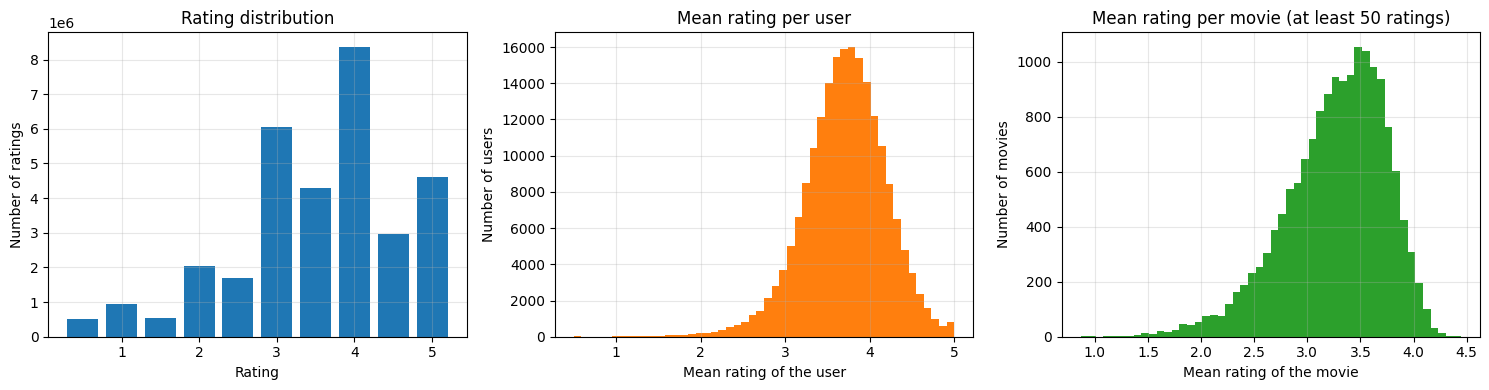

In [5]:
rating_values, rating_counts = np.unique(raw_ratings, return_counts=True)
for v, c in zip(rating_values, rating_counts):
  print(f"{v:.1f}: {c} ({c / len(raw_ratings):.1%})")
print("mean rating:", round(float(raw_ratings.mean()), 3), " std:", round(float(raw_ratings.std()), 3))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

ax1.bar(rating_values, rating_counts, width=0.4, color="tab:blue")
ax1.set_xlabel("Rating")
ax1.set_ylabel("Number of ratings")
ax1.set_title("Rating distribution")
ax1.grid(True, alpha=0.3)

ax2.hist(user_mean, bins=50, color="tab:orange")
ax2.set_xlabel("Mean rating of the user")
ax2.set_ylabel("Number of users")
ax2.set_title("Mean rating per user")
ax2.grid(True, alpha=0.3)

ax3.hist(item_mean[item_degrees >= 50], bins=50, color="tab:green")
ax3.set_xlabel("Mean rating of the movie")
ax3.set_ylabel("Number of movies")
ax3.set_title("Mean rating per movie (at least 50 ratings)")
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##Movie popularity and long tail

top 1% of movies (844) hold 54.8% of all ratings
top 5% of movies (4221) hold 88.6% of all ratings
top 10% of movies (8443) hold 95.7% of all ratings
top 20% of movies (16886) hold 98.6% of all ratings
movies needed for 50% of the ratings: 691
movies needed for 80% of the ratings: 2539
movies with fewer than 10 ratings: 52471 (62.1%)
movies with fewer than 100 ratings: 72241 (85.6%)
movies with fewer than 1000 ratings: 80035 (94.8%)
most rated movies:
  Shawshank Redemption, The (1994): 102929
  Forrest Gump (1994): 100296
  Pulp Fiction (1994): 98409
  Matrix, The (1999): 93808
  Silence of the Lambs, The (1991): 90330
  Star Wars: Episode IV - A New Hope (1977): 85010
  Fight Club (1999): 77332
  Jurassic Park (1993): 75233
  Schindler's List (1993): 73849
  Lord of the Rings: The Fellowship of the Ring, The (2001): 73122


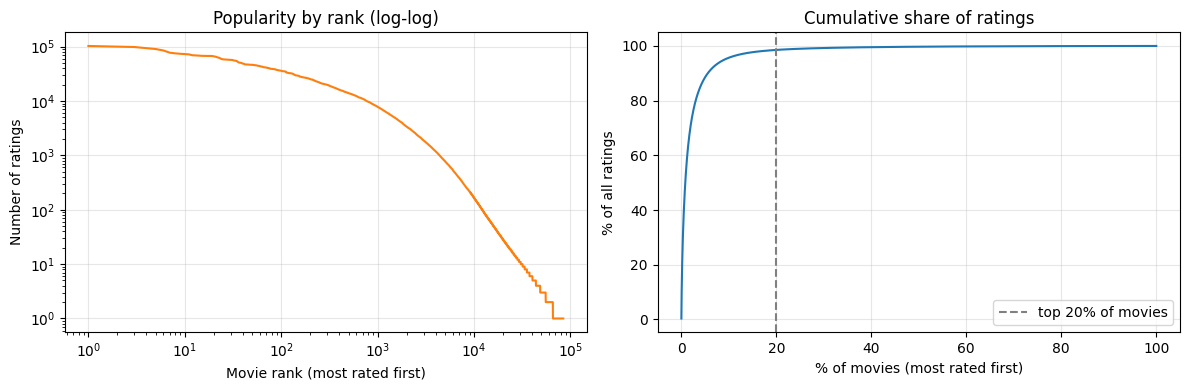

In [8]:

order = np.argsort(-item_degrees)
sorted_degrees = item_degrees[order]
cumulative = np.cumsum(sorted_degrees) / sorted_degrees.sum()
share_of_items = np.arange(1, len(sorted_degrees) + 1) / len(sorted_degrees)

for share in [0.01, 0.05, 0.1, 0.2]:
  k = max(int(share * len(sorted_degrees)), 1)
  print(f"top {share:.0%} of movies ({k}) hold {cumulative[k - 1]:.1%} of all ratings")
print("movies needed for 50% of the ratings:", np.searchsorted(cumulative, 0.5) + 1)
print("movies needed for 80% of the ratings:", np.searchsorted(cumulative, 0.8) + 1)
for t in [10, 100, 1000]:
  print(f"movies with fewer than {t} ratings: {(item_degrees < t).sum()} ({(item_degrees < t).mean():.1%})")

titles_by_id = dict(zip(movies.movieId, movies.title))
print("most rated movies:")
for j in order[:10]:
  print(f"  {titles_by_id.get(item_ids[j], '?')}: {item_degrees[j]}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.loglog(np.arange(1, len(sorted_degrees) + 1), sorted_degrees, color="tab:orange")
ax1.set_xlabel("Movie rank (most rated first)")
ax1.set_ylabel("Number of ratings")
ax1.set_title("Popularity by rank (log-log)")
ax1.grid(True, alpha=0.3)

ax2.plot(share_of_items * 100, cumulative * 100, color="tab:blue")
ax2.axvline(20, color="gray", linestyle="--", label="top 20% of movies")
ax2.set_xlabel("% of movies (most rated first)")
ax2.set_ylabel("% of all ratings")
ax2.set_title("Cumulative share of ratings")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##User-item matrix sparsity

users: 200948  movies: 84432  ratings: 32000204
density: 0.1886%   sparsity: 99.8114%
a dense user-movie matrix would need about 68 GB (float32)
ratings per user: min 20, 25% 36, median 73, 75% 167, 90% 364, 99% 1290, max 33332, mean 159.2
ratings per movie: min 1, 25% 2, median 5, 75% 25, 90% 249, 99% 9263, max 102929, mean 379.0


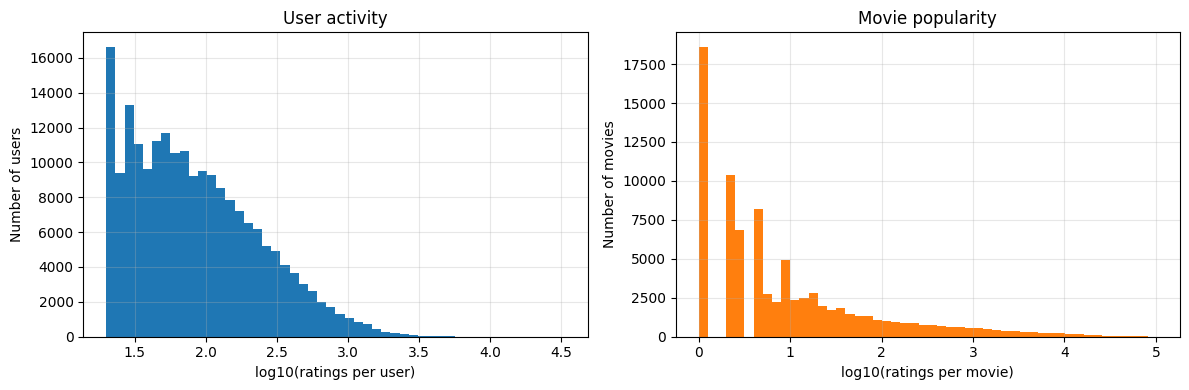

In [11]:
number_of_users = len(user_ids)
number_of_items = len(item_ids)
number_of_ratings = len(raw_ratings)
density = number_of_ratings / (number_of_users * number_of_items)

print("users:", number_of_users, " movies:", number_of_items, " ratings:", number_of_ratings)
print(f"density: {density:.4%}   sparsity: {1 - density:.4%}")
print(f"a dense user-movie matrix would need about {number_of_users * number_of_items * 4 / 1e9:.0f} GB (float32)")

for name, degrees in [("user", user_degrees), ("movie", item_degrees)]:
  p = np.percentile(degrees, [25, 50, 75, 90, 99])
  print(f"ratings per {name}: min {degrees.min()}, 25% {p[0]:.0f}, median {p[1]:.0f}, 75% {p[2]:.0f}, 90% {p[3]:.0f}, 99% {p[4]:.0f}, max {degrees.max()}, mean {degrees.mean():.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.hist(np.log10(user_degrees), bins=50, color="tab:blue")
ax1.set_xlabel("log10(ratings per user)")
ax1.set_ylabel("Number of users")
ax1.set_title("User activity")
ax1.grid(True, alpha=0.3)

ax2.hist(np.log10(item_degrees), bins=50, color="tab:orange")
ax2.set_xlabel("log10(ratings per movie)")
ax2.set_ylabel("Number of movies")
ax2.set_title("Movie popularity")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

##Genre distribution

movies in movies.csv without any rating: 3153
               Drama:  34175 movies,   13973271 ratings, mean rating 3.682
              Comedy:  23124 movies,   11206926 ratings, mean rating 3.432
            Thriller:  11823 movies,    8679464 ratings, mean rating 3.532
             Romance:  10369 movies,    5524615 ratings, mean rating 3.545
              Action:   9668 movies,    9665213 ratings, mean rating 3.476
         Documentary:   9363 movies,     427353 ratings, mean rating 3.691
              Horror:   8654 movies,    2492315 ratings, mean rating 3.307
  (no genres listed):   7080 movies,      55498 ratings, mean rating 3.368
               Crime:   6976 movies,    5373051 ratings, mean rating 3.692
           Adventure:   5402 movies,    7590522 ratings, mean rating 3.523
              Sci-Fi:   4907 movies,    5717337 ratings, mean rating 3.492
           Animation:   4617 movies,    2214562 ratings, mean rating 3.615
            Children:   4520 movies,    2731841 rating

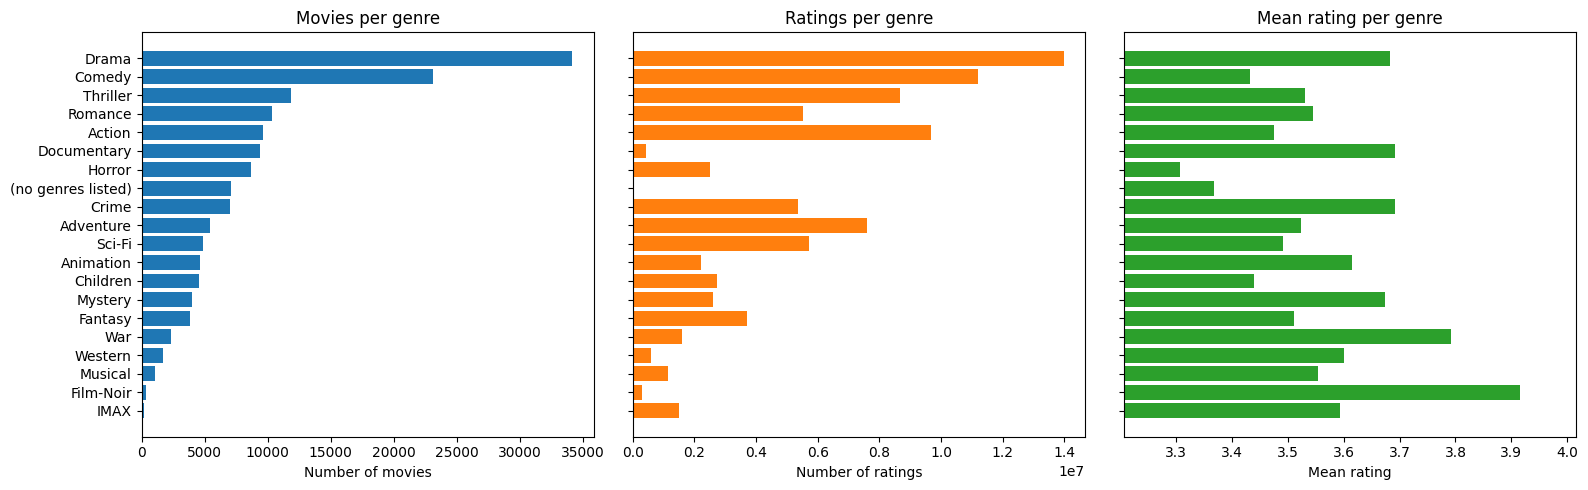

In [12]:
genres_by_item = pd.Series(item_ids).map(dict(zip(movies.movieId, movies.genres))).fillna("").to_numpy()

genre_movies = Counter()
for g in movies.genres.fillna("(no genres listed)"):
  for name in g.split("|"):
   genre_movies[name] += 1

genre_ratings = Counter()
genre_sums = Counter()
for g, d, s in zip(genres_by_item, item_degrees, item_sums):
  for name in g.split("|"):
    genre_ratings[name] += int(d)
    genre_sums[name] += float(s)

genres = [g for g, _ in genre_movies.most_common()]
genre_mean = [genre_sums[g] / max(genre_ratings[g], 1) for g in genres]

print("movies in movies.csv without any rating:", len(movies) - len(item_ids))
for g, m in zip(genres, genre_mean):
  print(f"{g:>20}: {genre_movies[g]:>6} movies, {genre_ratings[g]:>10} ratings, mean rating {m:.3f}")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
y = np.arange(len(genres))

ax1.barh(y, [genre_movies[g] for g in genres], color="tab:blue")
ax1.set_yticks(y)
ax1.set_yticklabels(genres)
ax1.invert_yaxis()
ax1.set_xlabel("Number of movies")
ax1.set_title("Movies per genre")

ax2.barh(y, [genre_ratings[g] for g in genres], color="tab:orange")
ax2.set_xlabel("Number of ratings")
ax2.set_title("Ratings per genre")

ax3.barh(y, genre_mean, color="tab:green")
ax3.set_xlim(min(genre_mean) - 0.1, max(genre_mean) + 0.1)
ax3.set_xlabel("Mean rating")
ax3.set_title("Mean rating per genre")

plt.tight_layout()
plt.show()

#Practical 2


The user + item biases code with alternating least squares will look like this:
```
user_biases = np.zeros((M))
item_biases = np.zeros((N))

repeat:
  for m in 0 .. M-1:
    bias = 0
    item_counter = 0
    for (n, r) in get_items_and_ratings_for_user(m):
      bias += lambda * (r - item_bias[n])
      item_counter += 1
    bias = bias / (lambda * item_counter + gamma)
    user_bias[m] = bias
```


repeat:
for m in 0 .. M-1:
...
for (n, r) in get_items_and_ratings_for_user(m):
sum things to update bias
user_bias[m] = ...

for (n, r) in get_items_and_ratings_for_user(m):
sum things to trait vector
user_vector[m,:] = ...

 now do the same for the items
for n in 0 .. N-1:


In [44]:
from math import sqrt
import numpy as np
user_biases = np.zeros(len(data.index_to_user))
item_biases = np.zeros(len(data.index_to_item))
# user_embeddings = np.random(len(40)) ## practical 3 should be mtrix
# item_embedding = np.random(len(40))  ## practical 3 matrix
lampda = 0.09
gamma = 0.1
tau = 0.9


## using ALS to get user and item biases

num_of_epochs = 10
loss_log_train = []
loss_log_test = []
nll_train = []
for epoch in range (num_of_epochs):
  ## users biases part
  for user in range (len(data.index_to_user)):
    bias = 0
    item_counter = 0
    for (n,r) in data.data_by_user_train[user]: ## was data.data_by_user but changed it in practical 2 to train the model from training data after split directly
      bias += lampda * (float(r) - item_biases[data.item_to_index[n]])
      item_counter += 1  ## for avging the bias
    bias = bias / (lampda * item_counter + gamma)
    user_biases[user] = bias


  ## item biases part
  for item in range (len(data.index_to_item)):
    bias = 0
    item_counter = 0
    for (n,r) in data.data_by_item_train[item]: ## was data.data_by_item but changed it in practical 2 to train the model from training data after split directly
      bias += lampda * (float(r) - user_biases[data.user_to_index[n]])
      item_counter += 1
    bias = bias / (lampda * item_counter + gamma)
    item_biases[item] = bias

  ## now we calculate the loss (data_by_user_train)
  error1 = 0
  error2 = 0
  N1 = 0
  N2 = 0
  for user_index in range(len(data.index_to_user)):
    for (n, r) in data.data_by_user_train[user_index]:
      pred_1 = (float(r) - (item_biases[data.item_to_index[n]]+ user_biases[user_index]))**2  ## something WRONG (brackets not included)
      error1 += pred_1
      N1 += 1
    for (n, r) in data.data_by_user_test[user_index]:
      pred_2 = (float(r) - (item_biases[data.item_to_index[n]]+ user_biases[user_index]))**2  ## WRONG BRACKETS
      error2 += pred_2
      N2 += 1

  reg = (gamma/2) * (np.square(user_biases).sum() + np.square(item_biases).sum())
  objective_train = (lampda/2) * error1 + reg
  nll_train.append(objective_train)

  mean_sqr_error_user_train = error1 /  N1
  mean_sqr_error_user_test = error2 / N2

  rmse_train = sqrt(mean_sqr_error_user_train)
  rmse_test = sqrt(mean_sqr_error_user_test)
  loss_log_train.append(rmse_train)
  loss_log_test.append(rmse_test)

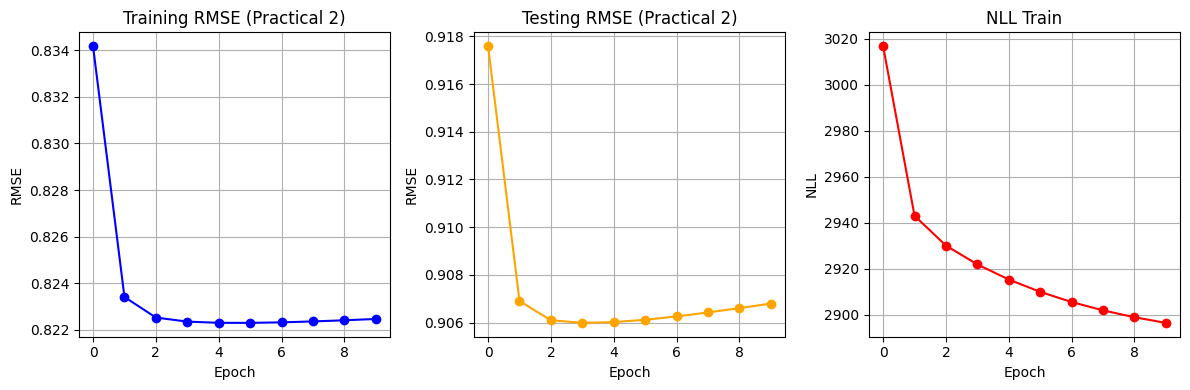

In [45]:
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

ax1.plot(loss_log_train, marker='o', color='blue')
ax1.set_title('Training RMSE (Practical 2)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.grid(True)

ax2.plot(loss_log_test, marker='o', color='orange')
ax2.set_title('Testing RMSE (Practical 2)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('RMSE')
ax2.grid(True)

ax3.plot(nll_train, marker='o', color='red')
ax3.set_title('NLL Train')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('NLL')
ax3.grid(True)





plt.tight_layout()
plt.show()

In [35]:
# print (user_biases)
print (item_biases)

[ 0.66453883  0.15825427  0.32501599 ... -0.36346533 -0.12662322
 -0.60030743]


#Practical 3: Adding user and items embeddings

In [46]:
from math import sqrt
import numpy as np
user_biases = np.zeros(len(data.index_to_user))
item_biases = np.zeros(len(data.index_to_item))

embedding_dim = 20
Identity_matrix = np.eye(embedding_dim)

user_embeddings = np.random.normal(0, 0.1, size = (len(data.index_to_user), embedding_dim))
item_embeddings = np.random.normal(0, 0.1, size = (len(data.index_to_item), embedding_dim))
lampda = 0.09
gamma = 0.1
tau = 0.9


## using ALS to get user and item biases

num_of_epochs = 10
loss_log_train = []
loss_log_test = []
nll_log = []
for epoch in range (num_of_epochs):


  ## users biases part
  for user in range (len(data.index_to_user)):
    bias = 0
    item_counter = 0
    for (n,r) in data.data_by_user_train[user]: ## was data.data_by_user but changed it in practical 2 to train the model from training data after split directly
      bias += lampda * (float(r) - np.dot(user_embeddings[user].T, item_embeddings[data.item_to_index[n]])-item_biases[data.item_to_index[n]])
      item_counter += 1  ## for avging the bias
    bias = bias / (lampda * item_counter + gamma)
    user_biases[user] = bias


  ##users embeddings
  for user in range (len(data.index_to_user)):
    embeddings_part1 = np.zeros((embedding_dim,embedding_dim))
    embedding_part2 = np.zeros(embedding_dim)
    for (n, r) in data.data_by_user_train[user]:
      embeddings_part1 += lampda * np.outer(item_embeddings[data.item_to_index[n]], item_embeddings[data.item_to_index[n]])
      embedding_part2 += lampda * item_embeddings[data.item_to_index[n]]*(float(r) - user_biases[user] - item_biases[data.item_to_index[n]])
    tau_Identity = tau * Identity_matrix
    part1 = embeddings_part1 + tau_Identity
    user_embeddings[user] = np.linalg.solve(part1, embedding_part2)



  ## item biases part
  for item in range (len(data.index_to_item)):
    bias = 0
    item_counter = 0
    for (n,r) in data.data_by_item_train[item]: ## was data.data_by_item but changed it in practical 2 to train the model from training data after split directly
      bias += lampda * (float(r) -( np.dot(user_embeddings[data.user_to_index[n]].T, item_embeddings[item]) + user_biases[data.user_to_index[n]]))
      item_counter += 1
    bias = bias / (lampda * item_counter + gamma)
    item_biases[item] = bias



  for item in range (len(data.index_to_item)):
    embeddings_part1 = np.zeros((embedding_dim,embedding_dim))
    embedding_part2 = np.zeros(embedding_dim)
    for (n, r) in data.data_by_item_train[item]:
      embeddings_part1 += lampda * np.outer(user_embeddings[data.user_to_index[n]], user_embeddings[data.user_to_index[n]])
      embedding_part2 += lampda * user_embeddings[data.user_to_index[n]]*(float(r) - item_biases[item] - user_biases[data.user_to_index[n]])
    tau_Identity = tau * Identity_matrix
    part1 = embeddings_part1 + tau_Identity
    item_embeddings[item] = np.linalg.solve(part1, embedding_part2)


  ## now we calculate the loss (data_by_user_train)
  error1 = 0
  error2 = 0
  N1 = 0
  N2 = 0
  for user_index in range(len(data.index_to_user)):
    for (n, r) in data.data_by_user_train[user_index]:
      pred_1 = (float(r) - (np.inner(user_embeddings[user_index], item_embeddings[data.item_to_index[n]]) + item_biases[data.item_to_index[n]]+ user_biases[user_index]))**2
      error1 += pred_1
      N1 += 1
    for (n, r) in data.data_by_user_test[user_index]:
      pred_2 = (float(r) - ( np.inner(user_embeddings[user_index], item_embeddings[data.item_to_index[n]])+ item_biases[data.item_to_index[n]] + user_biases[user_index]))**2
      error2 += pred_2
      N2 += 1

  reg_bias = (gamma/2) * (np.square(user_biases).sum() + np.square(item_biases).sum())
  reg_emb = (tau/2) * (np.square(user_embeddings).sum() + np.square(item_embeddings).sum())
  nll = (lampda/2) * error1 + reg_bias + reg_emb
  nll_log.append(nll)

  mean_sqr_error_user_train = error1 /  N1
  mean_sqr_error_user_test = error2 / N2


  rmse_train = sqrt(mean_sqr_error_user_train)
  rmse_test = sqrt(mean_sqr_error_user_test)
  loss_log_train.append(rmse_train)
  loss_log_test.append(rmse_test)

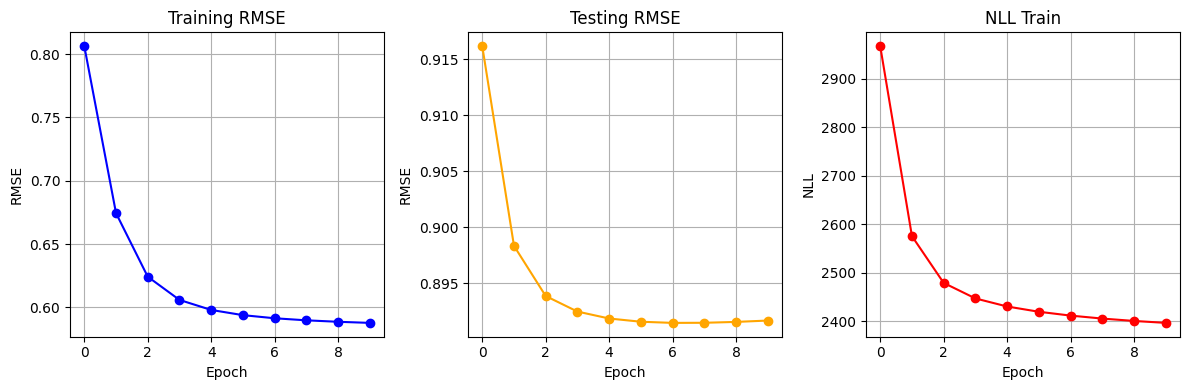

In [47]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

ax1.plot(loss_log_train, marker='o', color='blue')
ax1.set_title('Training RMSE')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.grid(True)

ax2.plot(loss_log_test, marker='o', color='orange')
ax2.set_title('Testing RMSE')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('RMSE')
ax2.grid(True)

ax3.plot(nll_log, marker='o', color='red')
ax3.set_title('NLL Train')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('NLL')
ax3.grid(True)



plt.tight_layout()
plt.show()

#Practical 4

##Loading data with CSR



In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

class RatingMap:

  def __init__(self, path, chunk_size=2_000_000, data_count=None):

    self.split_cutoff = 0.2

    ## read the csv in chunks, keep only user, item, rating
    users_chunks = []
    items_chunks = []
    ratings_chunks = []
    rows_loaded = 0

    for chunk in pd.read_csv(path+"/ratings.csv", names=["u", "i", "r"], header=0, usecols=[0, 1, 2],
                            dtype={"u": np.int32, "i": np.int32, "r": np.float32}, chunksize=chunk_size):
      if data_count is not None:
        remaining = data_count - rows_loaded
        if remaining <= 0:
          break
        if len(chunk) > remaining:
          chunk = chunk.iloc[:remaining]

      users_chunks.append(chunk["u"].to_numpy())
      items_chunks.append(chunk["i"].to_numpy())
      ratings_chunks.append(chunk["r"].to_numpy())

      rows_loaded += len(chunk)
      if data_count is not None and rows_loaded >= data_count:
        break

    raw_users = np.concatenate(users_chunks)
    raw_items = np.concatenate(items_chunks)
    ratings = np.concatenate(ratings_chunks)
    del users_chunks, items_chunks, ratings_chunks

    ## map raw ids to indices 0..n-1
    self.index_to_user, user_of_each_rating = np.unique(raw_users, return_inverse=True)
    self.index_to_item, item_of_each_rating = np.unique(raw_items, return_inverse=True)
    del raw_users, raw_items

    self.index_to_user = self.index_to_user.tolist()
    self.index_to_item = self.index_to_item.tolist()
    self.user_to_index = {u: i for i, u in enumerate(self.index_to_user)}
    self.item_to_index = {i: j for j, i in enumerate(self.index_to_item)}

    self.number_of_users = len(self.index_to_user)
    self.number_of_items = len(self.index_to_item)

    ## degrees (for the power law plot)
    self.user_degrees = np.bincount(user_of_each_rating, minlength=self.number_of_users)
    self.item_degrees = np.bincount(item_of_each_rating, minlength=self.number_of_items)

    ## train-test split
    mask = np.random.default_rng().random(len(ratings), dtype=np.float32) > self.split_cutoff

    train_users = user_of_each_rating[mask].tolist()
    train_items = item_of_each_rating[mask].tolist()
    train_ratings = ratings[mask].tolist()

    test_users = user_of_each_rating[~mask].tolist()
    test_items = item_of_each_rating[~mask].tolist()
    test_ratings = ratings[~mask].tolist()
    del user_of_each_rating, item_of_each_rating, ratings, mask

    ## data by user / by item (train), each entry is (id, rating)
    self.data_by_user_train = [[] for _ in range(self.number_of_users)]
    self.data_by_item_train = [[] for _ in range(self.number_of_items)]
    for u, i, r in zip(train_users, train_items, train_ratings):
      self.data_by_user_train[u].append((self.index_to_item[i], r))
      self.data_by_item_train[i].append((self.index_to_user[u], r))

    ## data by user / by item (test)
    self.data_by_user_test = [[] for _ in range(self.number_of_users)]
    self.data_by_item_test = [[] for _ in range(self.number_of_items)]
    for u, i, r in zip(test_users, test_items, test_ratings):
      self.data_by_user_test[u].append((self.index_to_item[i], r))
      self.data_by_item_test[i].append((self.index_to_user[u], r))

  def plot_powerlaw(self):
    user_deg = Counter(self.user_degrees.tolist())
    item_deg = Counter(self.item_degrees.tolist())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    for ax in (ax1, ax2):
      ax.plot(list(item_deg.keys()), list(item_deg.values()),
      marker=".", linestyle="none", color="tab:orange", label="Movies")
      ax.plot(list(user_deg.keys()), list(user_deg.values()),
      marker=".", linestyle="none", color="tab:blue", label="Users")
      ax.set_xlabel("Degree")
      ax.set_ylabel("Frequency")
      ax.grid(True)
      ax.legend()

    ax1.set_title("Normal scale")
    ax2.set_title("Log-log scale")
    ax2.set_xscale("log")
    ax2.set_yscale("log")

    plt.tight_layout()
    plt.show()

In [7]:
data = RatingMap(path)

In [9]:
from math import sqrt
import numpy as np

def predict(user_index, item_index, user_embeddings, item_embeddings, user_biases, item_biases):
  return np.inner(user_embeddings[user_index], item_embeddings[item_index]) + user_biases[user_index] + item_biases[item_index]


def rmse_calculation(data_by_user, user_embeddings, item_embeddings, user_biases, item_biases):
    error = 0
    N = 0
    for user_index in range(len(data.index_to_user)):
      for (n, r) in data_by_user[user_index]:
        pred = predict(user_index, data.item_to_index[n], user_embeddings, item_embeddings, user_biases, item_biases)
        error += (float(r) - pred)**2
        N += 1
    return sqrt(error / N)

##CSR without Numba

In [13]:
import numpy as np
from math import sqrt

num_of_epochs = 30
lampda = 0.01
gamma = 0.005
tau = 0.01
embedding_dim = 32
Identity_matrix = np.eye(embedding_dim)

user_biases = np.zeros(len(data.index_to_user))
item_biases = np.zeros(len(data.index_to_item))
user_embeddings = np.random.normal(0, 0.1, size = (len(data.index_to_user), embedding_dim))
item_embeddings = np.random.normal(0, 0.1, size = (len(data.index_to_item), embedding_dim))

## index / rating arrays built once from data_by_user_train, data_by_item_train, data_by_user_test
user_items_train = [np.array([data.item_to_index[n] for (n, r) in data.data_by_user_train[user]], dtype=int) for user in range(len(data.index_to_user))]
user_ratings_train = [np.array([float(r) for (n, r) in data.data_by_user_train[user]]) for user in range(len(data.index_to_user))]
item_users_train = [np.array([data.user_to_index[n] for (n, r) in data.data_by_item_train[item]], dtype=int) for item in range(len(data.index_to_item))]
item_ratings_train = [np.array([float(r) for (n, r) in data.data_by_item_train[item]]) for item in range(len(data.index_to_item))]
user_items_test = [np.array([data.item_to_index[n] for (n, r) in data.data_by_user_test[user]], dtype=int) for user in range(len(data.index_to_user))]
user_ratings_test = [np.array([float(r) for (n, r) in data.data_by_user_test[user]]) for user in range(len(data.index_to_user))]

loss_log_train = []
loss_log_test = []
nll_log = []
for epoch in range (num_of_epochs):

  ## users biases part
  for user in range (len(data.index_to_user)):
    items = user_items_train[user]
    bias = lampda * (user_ratings_train[user] - item_embeddings[items] @ user_embeddings[user] - item_biases[items]).sum()
    user_biases[user] = bias / (lampda * len(items) + gamma)

  ## users embeddings part
  for user in range (len(data.index_to_user)):
    items = user_items_train[user]
    Vu = item_embeddings[items]
    y = user_ratings_train[user] - item_biases[items] - user_biases[user]
    user_embeddings[user] = np.linalg.solve(lampda * (Vu.T @ Vu) + gamma * Identity_matrix, lampda * (Vu.T @ y))

  ## item biases part
  for item in range (len(data.index_to_item)):
    users = item_users_train[item]
    bias = lampda * (item_ratings_train[item] - user_embeddings[users] @ item_embeddings[item] - user_biases[users]).sum()
    item_biases[item] = bias / (lampda * len(users) + gamma)

  ## item embeddings part
  for item in range (len(data.index_to_item)):
    users = item_users_train[item]
    Uv = user_embeddings[users]
    y = item_ratings_train[item] - user_biases[users] - item_biases[item]
    item_embeddings[item] = np.linalg.solve(lampda * (Uv.T @ Uv) + tau * Identity_matrix, lampda * (Uv.T @ y))

  ## now we calculate the loss
  error1 = 0
  error2 = 0
  N1 = 0
  N2 = 0
  for user_index in range(len(data.index_to_user)):
    items = user_items_train[user_index]
    error1 += ((user_ratings_train[user_index] - (item_embeddings[items] @ user_embeddings[user_index] + item_biases[items] + user_biases[user_index]))**2).sum()
    N1 += len(items)
    items = user_items_test[user_index]
    error2 += ((user_ratings_test[user_index] - (item_embeddings[items] @ user_embeddings[user_index] + item_biases[items] + user_biases[user_index]))**2).sum()
    N2 += len(items)

  nll = ((lampda/2) * error1
    + (gamma/2) * np.square(user_embeddings).sum()
    + (tau/2) * np.square(item_embeddings).sum()
    + (gamma/2) * (np.square(user_biases).sum() + np.square(item_biases).sum()))
  nll_log.append(nll)

  rmse_train = sqrt(error1 / N1)
  rmse_test = sqrt(error2 / N2)
  loss_log_train.append(rmse_train)
  loss_log_test.append(rmse_test)
  print(epoch, nll, rmse_train, rmse_test)

0 84849.75063703509 0.7547414754663545 0.9311604454959209
1 69853.47640991019 0.6766757132815113 0.8816792869979586
2 63649.903507773335 0.6433284141706803 0.8577925593567747
3 60450.68283432463 0.6263294310127415 0.846701359244036
4 58484.092837991724 0.6162010387243222 0.8409823379507132
5 57143.43174153284 0.6095731489955659 0.8379985411527291
6 56170.96599879673 0.6049879974967215 0.8366440047281238
7 55431.03817531291 0.6016730442606252 0.8362908394126909
8 54845.83028301064 0.5991857495100824 0.8365388344356167
9 54368.31579600361 0.5972605065732993 0.8371406656299278
10 53968.72310171071 0.5957310686421872 0.8379518014344649
11 53627.41551276118 0.5944894071771345 0.8388888783533708
12 53330.969833517294 0.5934628837993654 0.839901510827709
13 53069.90694538084 0.5926010662785437 0.8409572910123998
14 52837.34026717272 0.5918679961028642 0.8420345987351312
15 52628.14189851988 0.5912374688173245 0.8431181111504429
16 52438.4077608245 0.5906899777569153 0.8441964885227041
17 5226

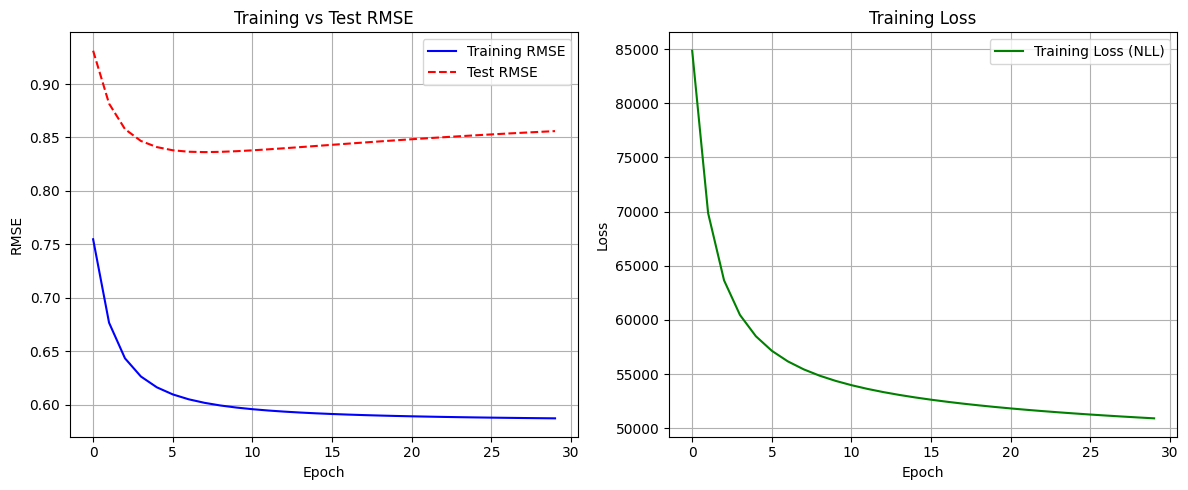

In [14]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

## train vs test rmse
ax1.plot(loss_log_train, color='blue', linestyle='-', label='Training RMSE')
ax1.plot(loss_log_test, color='red', linestyle='--', label='Test RMSE')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.set_title('Training vs Test RMSE')
ax1.legend()
ax1.grid(True)

## nll
ax2.plot(nll_log, color='green', linestyle='-', label='Training Loss (NLL)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Training Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

##Using Numba


In [15]:
import numpy as np
import numba as nb

@nb.njit(parallel=True, fastmath=True)
def update_side(pointers, others, rates, other_embeddings, other_biases, embeddings, biases, lampda, gamma, reg):
  n = len(pointers) - 1
  embedding_dim = embeddings.shape[1]
  for idx in nb.prange(n):
    s, e = pointers[idx], pointers[idx + 1]

    ## bias, using the current embedding
    total = 0.0
    for p in range(s, e):
      o = others[p]
      pred = other_biases[o]
      for a in range(embedding_dim):
       pred += other_embeddings[o, a] * embeddings[idx, a]
      total += rates[p] - pred
    biases[idx] = lampda * total / (lampda * (e - s) + gamma)

    ## embedding, using the new bias: A = sum v v^T and b = sum v y
    A = np.zeros((embedding_dim, embedding_dim))
    b = np.zeros(embedding_dim)
    for p in range(s, e):
      o = others[p]
      y = rates[p] - other_biases[o] - biases[idx]
      for a in range(embedding_dim):
        v = other_embeddings[o, a]
        b[a] += v * y
        for c in range(a, embedding_dim):
          A[a, c] += v * other_embeddings[o, c]

    for a in range(embedding_dim):
      for c in range(a):
       A[a, c] = A[c, a]
      A[a, a] = lampda * A[a, a] + reg
      for c in range(a + 1, embedding_dim):
        A[a, c] = lampda * A[a, c]
        A[c, a] = A[a, c]
    embeddings[idx] = np.linalg.solve(A, lampda * b)

In [16]:
import numpy as np
from math import sqrt

num_of_epochs = 30
lampda = 0.01
gamma = 0.005
tau = 0.01
embedding_dim = 32

## flat arrays (CSR) built from data_by_user_train / data_by_item_train / data_by_user_test
user_counts_train = np.array([len(data.data_by_user_train[user]) for user in range(len(data.index_to_user))])
users_pointers = np.concatenate([[0], np.cumsum(user_counts_train)])
items_by_user = np.array([data.item_to_index[n] for user in range(len(data.index_to_user)) for (n, r) in data.data_by_user_train[user]], dtype=np.int64)
ratings_by_users = np.array([float(r) for user in range(len(data.index_to_user)) for (n, r) in data.data_by_user_train[user]])

item_counts_train = np.array([len(data.data_by_item_train[item]) for item in range(len(data.index_to_item))])
items_pointers = np.concatenate([[0], np.cumsum(item_counts_train)])
users_by_items = np.array([data.user_to_index[n] for item in range(len(data.index_to_item)) for (n, r) in data.data_by_item_train[item]], dtype=np.int64)
ratings_by_items = np.array([float(r) for item in range(len(data.index_to_item)) for (n, r) in data.data_by_item_train[item]])

train_users = np.repeat(np.arange(len(data.index_to_user)), user_counts_train)
train_items = items_by_user
train_ratings = ratings_by_users

user_counts_test = np.array([len(data.data_by_user_test[user]) for user in range(len(data.index_to_user))])
test_users = np.repeat(np.arange(len(data.index_to_user)), user_counts_test)
test_items = np.array([data.item_to_index[n] for user in range(len(data.index_to_user)) for (n, r) in data.data_by_user_test[user]], dtype=np.int64)
test_ratings = np.array([float(r) for user in range(len(data.index_to_user)) for (n, r) in data.data_by_user_test[user]])

user_biases = np.zeros(len(data.index_to_user))
item_biases = np.zeros(len(data.index_to_item))
user_embeddings = np.random.normal(0, 0.1, size = (len(data.index_to_user), embedding_dim))
item_embeddings = np.random.normal(0, 0.1, size = (len(data.index_to_item), embedding_dim))


## sum of squared errors, chunked to keep memory low
def error_calculation(users, items, rates, user_embeddings, item_embeddings, user_biases, item_biases, chunk=1_000_000):
  error = 0
  for start in range(0, len(users), chunk):
    u = users[start:start+chunk]
    it = items[start:start+chunk]
    pred = np.einsum("nk,nk->n", user_embeddings[u], item_embeddings[it]) + user_biases[u] + item_biases[it]
    error += ((rates[start:start+chunk] - pred)**2).sum()
  return error


loss_log_train = []
loss_log_test = []
nll_log = []
for epoch in range (num_of_epochs):

  ## users part (biases then embeddings)
  update_side(users_pointers, items_by_user, ratings_by_users,
              item_embeddings, item_biases, user_embeddings, user_biases, lampda, gamma, gamma)

  ## items part (biases then embeddings)
  update_side(items_pointers, users_by_items, ratings_by_items,
              user_embeddings, user_biases, item_embeddings, item_biases, lampda, gamma, tau)

  ## now we calculate the loss
  error1 = error_calculation(train_users, train_items, train_ratings, user_embeddings, item_embeddings, user_biases, item_biases)
  error2 = error_calculation(test_users, test_items, test_ratings, user_embeddings, item_embeddings, user_biases, item_biases)

  nll = ((lampda/2) * error1
          + (gamma/2) * np.square(user_embeddings).sum()
          + (tau/2) * np.square(item_embeddings).sum()
          + (gamma/2) * (np.square(user_biases).sum() + np.square(item_biases).sum()))
  nll_log.append(nll)

  rmse_train = sqrt(error1 / len(train_ratings))
  rmse_test = sqrt(error2 / len(test_ratings))
  loss_log_train.append(rmse_train)
  loss_log_test.append(rmse_test)
  print(epoch, nll, rmse_train, rmse_test)

0 84808.68648017134 0.7544531060708786 0.9307587343684905
1 69765.84419723303 0.6760260683758321 0.880764775985451
2 63590.06514886174 0.6428219214014169 0.8571014596114289
3 60457.83126900963 0.6262452272300878 0.8465104580301096
4 58562.625609039984 0.6165766812789646 0.8414935138309878
5 57271.469755254446 0.6102714922763941 0.8390717933244644
6 56321.224238900904 0.6058349577164758 0.8379888117281078
7 55584.90289392518 0.6025481337791325 0.8376570220812692
8 54993.14561373532 0.6000222860417636 0.8377756002359977
9 54504.289699692046 0.5980266048590197 0.8381800385120588
10 54091.5597350436 0.5964143183511948 0.8387733230861891
11 53736.95538236417 0.595087984931016 0.8394943798584802
12 53427.93746817845 0.5939807895921222 0.8403023218537112
13 53155.45954975308 0.5930453100649352 0.8411685603830262
14 52912.77983193012 0.5922467183119323 0.8420727990116538
15 52694.741095151854 0.5915587083865519 0.8430005202476138
16 52497.32364039879 0.5909610313689811 0.8439412772529613
17 52

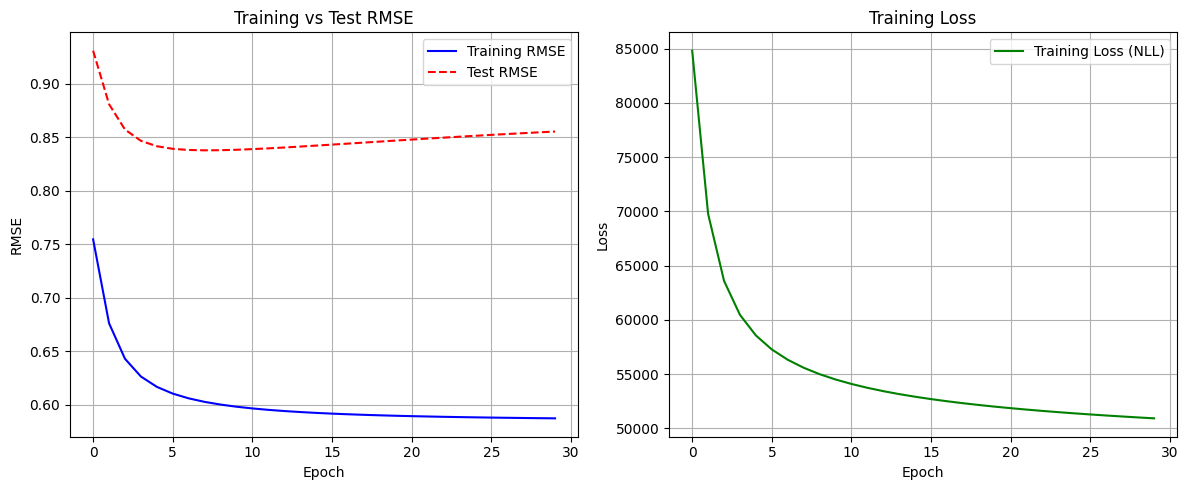

In [17]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

## train vs test rmse
ax1.plot(loss_log_train, color='blue', linestyle='-', label='Training RMSE')
ax1.plot(loss_log_test, color='red', linestyle='--', label='Test RMSE')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('RMSE')
ax1.set_title('Training vs Test RMSE')
ax1.legend()
ax1.grid(True)

## nll
ax2.plot(nll_log, color='green', linestyle='-', label='Training Loss (NLL)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_title('Training Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

##Cold-start analysis

overall test RMSE: 0.8552  global-mean baseline: 1.0585
movies with no training rating: 4252 of 84432
test ratings on those movies: 4812 (0.08% of the test set)
Test RMSE by training ratings of the movie
           0:      4812 test ratings (0.08%), model RMSE 1.0384, global-mean RMSE 1.3460
         1-4:     18327 test ratings (0.29%), model RMSE 0.9852, global-mean RMSE 1.3190
        5-19:     42587 test ratings (0.67%), model RMSE 0.9310, global-mean RMSE 1.2514
       20-99:    111350 test ratings (1.74%), model RMSE 0.9099, global-mean RMSE 1.1802
     100-999:    633873 test ratings (9.90%), model RMSE 0.8709, global-mean RMSE 1.1350
       1000+:   5590043 test ratings (87.33%), model RMSE 0.8510, global-mean RMSE 1.0440
Test RMSE by training ratings of the user
         <20:    101205 test ratings (1.58%), model RMSE 1.2818, global-mean RMSE 1.1428
       20-49:    559907 test ratings (8.75%), model RMSE 1.1614, global-mean RMSE 1.0882
       50-99:    805916 test ratings (12.

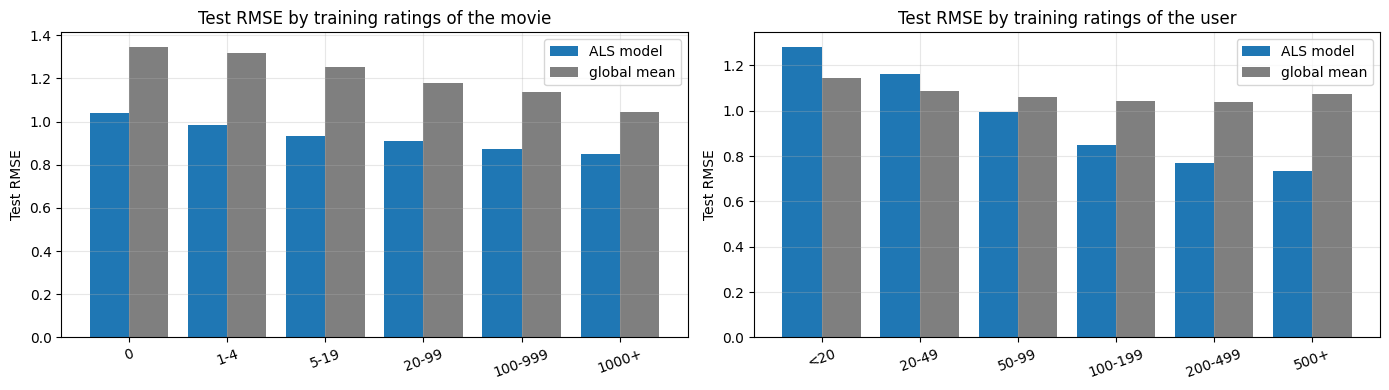

In [18]:
import numpy as np
import matplotlib.pyplot as plt

chunk = 1_000_000
test_pred = np.empty(len(test_ratings))
for start in range(0, len(test_ratings), chunk):
  u = test_users[start:start+chunk]
  it = test_items[start:start+chunk]
  test_pred[start:start+chunk] = np.einsum("nk,nk->n", user_embeddings[u], item_embeddings[it]) + user_biases[u] + item_biases[it]
test_error = (test_ratings - test_pred)**2
baseline_error = (test_ratings - train_ratings.mean())**2
print("overall test RMSE:", round(float(np.sqrt(test_error.mean())), 4), " global-mean baseline:", round(float(np.sqrt(baseline_error.mean())), 4))

## how many movies / test ratings have no training signal at all
no_train_items = item_counts_train == 0
print("movies with no training rating:", int(no_train_items.sum()), "of", len(item_counts_train))
print("test ratings on those movies:", int(no_train_items[test_items].sum()), f"({no_train_items[test_items].mean():.2%} of the test set)")

def bucket_report(counts, bins, names, title, ax):
  bucket = np.digitize(counts, bins)
  model_rmse = []
  base_rmse = []
  print(title)
  for b in range(len(names)):
    m = bucket == b
    if m.sum() == 0:
      model_rmse.append(np.nan)
      base_rmse.append(np.nan)
      continue
    model_rmse.append(np.sqrt(test_error[m].mean()))
    base_rmse.append(np.sqrt(baseline_error[m].mean()))
    print(f"  {names[b]:>10}: {m.sum():>9} test ratings ({m.mean():.2%}), model RMSE {model_rmse[-1]:.4f}, global-mean RMSE {base_rmse[-1]:.4f}")
  x = np.arange(len(names))
  ax.bar(x - 0.2, model_rmse, width=0.4, color="tab:blue", label="ALS model")
  ax.bar(x + 0.2, base_rmse, width=0.4, color="tab:gray", label="global mean")
  ax.set_xticks(x)
  ax.set_xticklabels(names, rotation=20)
  ax.set_ylabel("Test RMSE")
  ax.set_title(title)
  ax.legend()
  ax.grid(True, alpha=0.3)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

bucket_report(item_counts_train[test_items], [1, 5, 20, 100, 1000],
              ["0", "1-4", "5-19", "20-99", "100-999", "1000+"],
              "Test RMSE by training ratings of the movie", ax1)

bucket_report(user_counts_train[test_users], [20, 50, 100, 200, 500],
              ["<20", "20-49", "50-99", "100-199", "200-499", "500+"],
              "Test RMSE by training ratings of the user", ax2)

plt.tight_layout()
plt.show()

##Save model in disk

In [19]:
import numpy as np

item_counts = np.diff(items_pointers)
sum_r = np.bincount(train_items, weights=train_ratings, minlength=len(data.index_to_item))
sum_r2 = np.bincount(train_items, weights=train_ratings.astype(np.float64) ** 2, minlength=len(data.index_to_item))
mean_r = sum_r / np.maximum(item_counts, 1)
item_std = np.sqrt(np.maximum(sum_r2 / np.maximum(item_counts, 1) - mean_r ** 2, 0))

np.savez("item_model.npz",
          item_embeddings=item_embeddings, item_biases=item_biases,
          index_to_item=data.index_to_item, item_counts=item_counts, item_std=item_std,
          lampda=lampda, gamma=gamma, tau=tau,
          nll_log=nll_log, loss_log_train=loss_log_train, loss_log_test=loss_log_test)

np.savez("user_model.npz", user_embeddings=user_embeddings, user_biases=user_biases)

##Reading data from disk

In [20]:

import numpy as np
import pandas as pd

model = np.load("item_model.npz")
item_embeddings = model["item_embeddings"]
item_biases = model["item_biases"]
index_to_item = model["index_to_item"]
item_counts = model["item_counts"]
item_std = model["item_std"]

lampda = float(model["lampda"])
gamma = float(model["gamma"])
tau = float(model["tau"])

movies = pd.read_csv(path + "/movies.csv")
titles = pd.Series(index_to_item).map(dict(zip(movies.movieId, movies.title))).fillna("?").to_numpy()

def find(text):
  hits = np.flatnonzero(pd.Series(titles).str.contains(text, case=False, regex=False).to_numpy())
  for j in hits:
   print(j, titles[j], item_counts[j])
  return hits

##Dummy user test:

In [21]:
import numpy as np

def fold_in(item_idx, rates, item_embeddings, item_biases, lampda, gamma, n_iter=5):
  embedding_dim = item_embeddings.shape[1]
  item_idx = np.asarray(item_idx)
  rates = np.asarray(rates, dtype=np.float64)
  Vu = item_embeddings[item_idx]
  user_embedding = np.zeros(embedding_dim)
  for _ in range(n_iter):
    ## bias, using the current embedding
    resid = rates - Vu @ user_embedding - item_biases[item_idx]
    user_bias = lampda * resid.sum() / (lampda * len(rates) + gamma)
    ## embedding, using the new bias
    y = rates - item_biases[item_idx] - user_bias
    user_embedding = np.linalg.solve(lampda * (Vu.T @ Vu) + gamma * np.eye(embedding_dim), lampda * (Vu.T @ y))
  return user_embedding, user_bias

###Score then rank predictions

In [25]:
import numpy as np

def recommend(user_embedding, w=0.05, min_count=100, exclude=(), top=10):
  score = item_embeddings @ user_embedding + w * item_biases   ## no user bias, it doesn't change the ranking
  score[item_counts < min_count] = -np.inf                     ## drop movies with fewer than min_count training ratings
  score[list(exclude)] = -np.inf
  best = np.argsort(-score)[:top]
  return [(titles[j], round(float(score[j]), 3), int(item_counts[j])) for j in best]

hits = find("Toy Story")         ## pick the right index from the printout
x = hits[0]
user_embedding, user_bias = fold_in([x], [5.0], item_embeddings, item_biases, lampda, gamma, n_iter=5)
for row in recommend(user_embedding, w=0.05, min_count=500, exclude=[x]):
  print(row)

0 Toy Story (1995) 55243
3021 Toy Story 2 (1999) 26078
14810 Toy Story 3 (2010) 16280
20457 Toy Story of Terror (2013) 296
22510 Toy Story Toons: Hawaiian Vacation (2011) 112
22511 Toy Story Toons: Small Fry (2011) 104
23868 Toy Story Toons: Partysaurus Rex (2012) 71
23870 Toy Story That Time Forgot (2014) 274
58317 Toy Story 4 (2019) 2231
('Toy Story 2 (1999)', 3.307, 26078)
('Kurt & Courtney (1998)', 3.067, 507)
('Toy Story 3 (2010)', 3.01, 16280)
('Monsters, Inc. (2001)', 2.588, 36845)
('Louis C.K.: Chewed Up (2008)', 2.586, 1350)
("Bug's Life, A (1998)", 2.567, 21437)
('Incredibles, The (2004)', 2.565, 33159)
('Tarzan (1999)', 2.429, 6692)
('Finding Nemo (2003)', 2.398, 36927)
('Hercules (1997)', 2.32, 7197)


[('Drama', 2588), ('Comedy', 2060), ('Thriller', 1370), ('Action', 1293), ('Romance', 965), ('Adventure', 916), ('Crime', 787), ('Sci-Fi', 694), ('Horror', 565), ('Fantasy', 532)]
variance explained by PC1, PC2: [0.052 0.05 ]


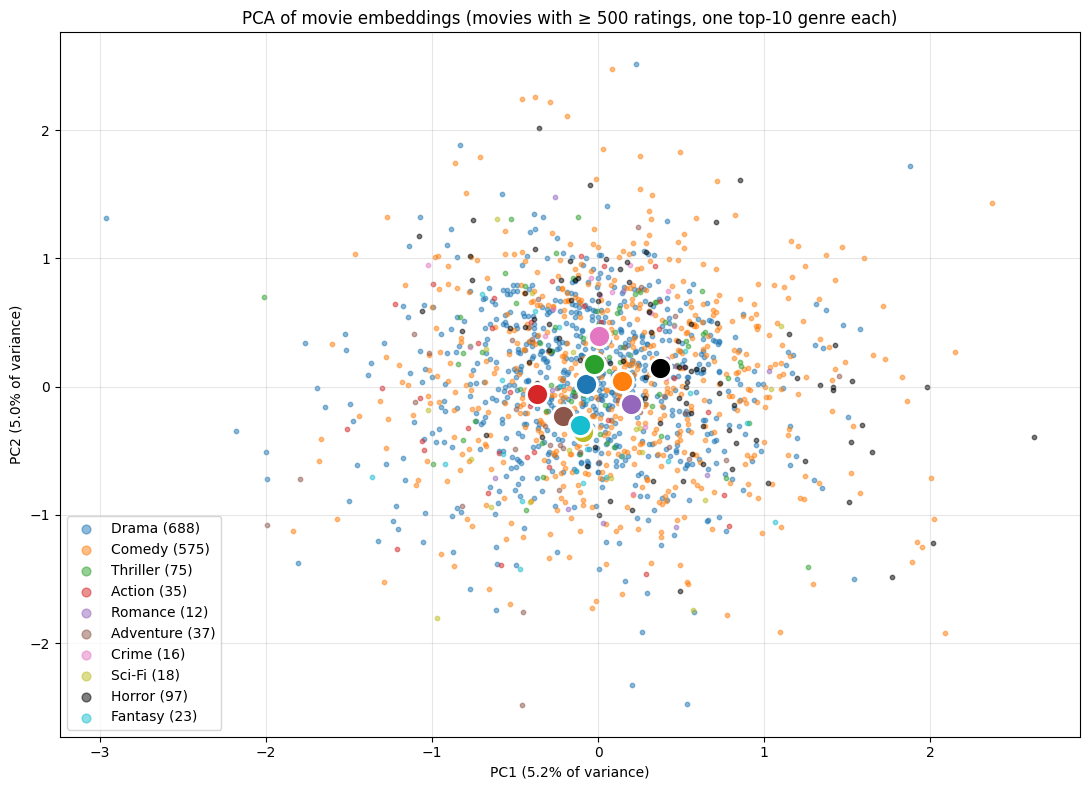

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

min_count = 500
keep = np.flatnonzero(item_counts >= min_count)

## genres per item index
genres_by_item = pd.Series(index_to_item).map(dict(zip(movies.movieId, movies.genres))).fillna("").to_numpy()
genre_lists = [g.split("|") for g in genres_by_item]

## top 10 genres among the kept movies
ignore = {"(no genres listed)", "IMAX", ""}
counter = Counter(g for j in keep for g in genre_lists[j] if g not in ignore)
top_genres = [g for g, _ in counter.most_common(10)]
print(counter.most_common(10))

## PCA on the item embeddings
X = item_embeddings[keep]
Xc = X - X.mean(axis=0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
coords = Xc @ Vt[:2].T
explained = S ** 2 / np.sum(S ** 2)
print("variance explained by PC1, PC2:", explained[:2].round(3))

## keep movies that belong to exactly one of the top 10 genres
label = []
for j in keep:
  genre_hits = [g for g in genre_lists[j] if g in top_genres]
  label.append(genre_hits[0] if len(genre_hits) == 1 else None)
label = np.array(label, dtype=object)
has_label = np.array([l is not None for l in label])

## colors: horror in black, the rest from tab10 without grey
palette = [c for i, c in enumerate(plt.cm.tab10.colors) if i != 7] + ["gold"]
colors, p = {}, 0
for g in top_genres:
  if g == "Horror":
    colors[g] = "black"
  else:
    colors[g] = palette[p]
    p += 1

fig, ax = plt.subplots(figsize=(11, 8))
for g in top_genres:
  m = has_label & (label == g)
  ax.scatter(coords[m, 0], coords[m, 1], s=10, alpha=0.5, color=colors[g], label=f"{g} ({m.sum()})")
  ax.scatter(coords[m, 0].mean(), coords[m, 1].mean(), s=250, color=colors[g],
             edgecolor="white", linewidth=2, zorder=5)

ax.set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
ax.set_title(f"PCA of movie embeddings (movies with ≥ {min_count} ratings, one top-10 genre each)")
ax.legend(markerscale=2, loc="best")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
import shutil
from google.colab import drive

drive.mount("/content/drive")
shutil.copy("/content/item_model.npz", "/content/drive/MyDrive/item_model.npz")
shutil.copy("/content/user_model.npz", "/content/drive/MyDrive/user_model.npz")
print("saved to Drive")

Mounted at /content/drive
saved to Drive
